In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import matplotlib.pyplot as plt
import matplotlib as mpl
import optax
import jax.numpy as jnp
import equinox as eqx

from pathlib import Path
from jax import random, vmap, jit
from jax.lax import scan

%config InlineBackend.figure_format='retina'

# $D=1$ elliptic equation and its finite element discretisation

The boundary value problem (BVP) we consider here

$$
-\frac{d}{dx} \left(a(x)\frac{d u(x)}{dx}\right) = f(x), \quad u(0) = u(1) = 0,
$$

is a one-dimensional case of a more general partial differential equation

$$
-\sum_{i=1}^{D}\frac{\partial}{\partial x_i} \left(a(x)\frac{\partial u(x)}{\partial x_i}\right) = f(x), \quad x \in \Gamma, \quad \left. u(x)\right|_{\partial \Gamma} = 0.
$$

The solution of the BVP can in general only be obtained approximately. The usual choice is to select a set of uniform nodes $x_i = ih,\ i=0,\dots, N+1$ with $h = \frac{1}{N+1}$, $N\in\mathbb{N}$. The nodes $x_0=0$ and $x_{N+1}=1$ are on the boundary, and $x_1,\dots,x_N$ are the $N$ interior nodes. We approximate $u(x)$ by a continuous function that is piecewise linear on each interval (*element*) $[x_i, x_{i+1}],\ i=0,\dots, N$. A convenient way to achieve that is to define a hat function:

$$
\phi_{i}(x) =
\begin{cases}
0,~x\notin [x_i - h, x_i + h];\\
\frac{1}{h}\left(x - x_i + h\right),~x\in [x_i - h, x_i];\\
\frac{1}{h}\left(x_i + h - x\right),~x\in [x_i, x_i + h].
\end{cases}
$$

Each $\phi_i$ equals $1$ at $x_i$ and $0$ at all other nodes, so any piecewise linear function $u_h(x)=\sum_i u_i\phi_i(x)$ has the nodal values as its coefficients: $u_h(x_i) = u_i$.

A couple of hat functions are given below:

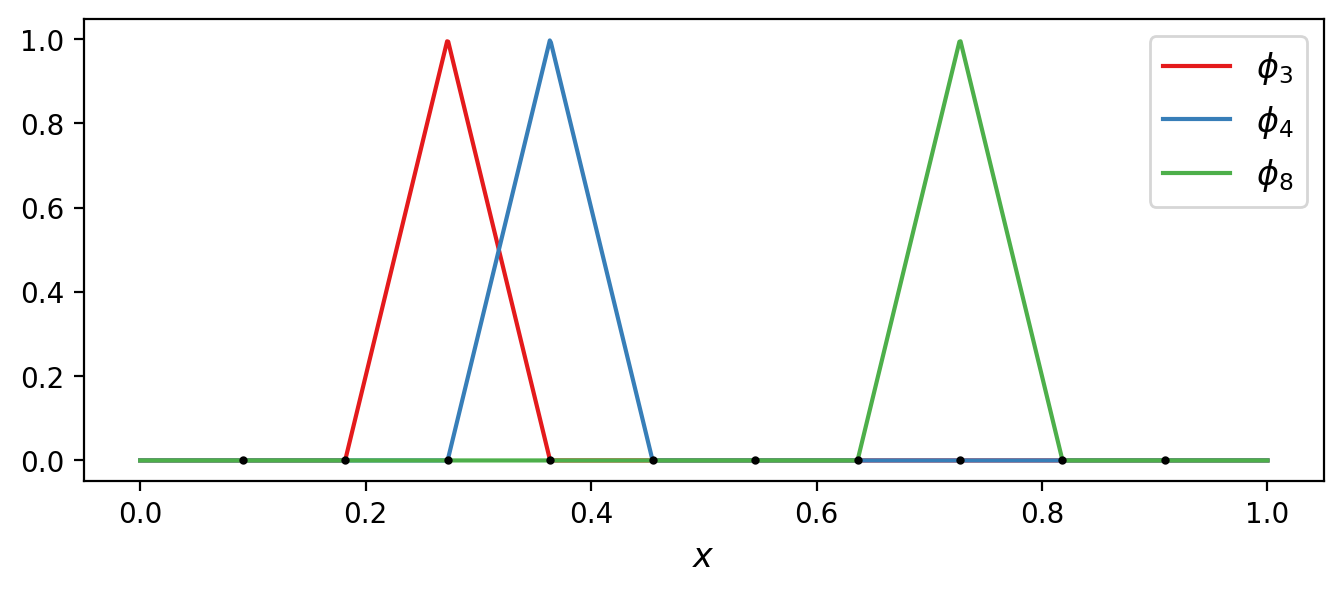

In [2]:
figure_name = "FEM_basis"
if figure_name is not None:
    # the repository root is the closest parent of the working directory that contains `notebooks`
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
    data_dir = root / "data"
    
    if not data_dir.exists():
        data_dir.mkdir()

colors = mpl.colormaps['Set1'].colors

def hat_function(x, i, N):
    # i = 1, ..., N enumerates interior nodes x_i = i / (N+1)
    h = 1 / (N + 1)
    return jnp.maximum(0.0, 1 - jnp.abs(x - i*h) / h)

N = 10
M = 1000
x = jnp.linspace(0, 1, M)
nodes = jnp.linspace(0, 1, N+2)[1:-1]

plt.figure(figsize=(8, 3))
for i, c in zip([3, 4, 8], colors):
    plt.plot(x, hat_function(x, i, N), label=f"$\\phi_{{{i}}}$", color=c)
plt.plot(nodes, jnp.zeros(N), "k.", markersize=4)
plt.xlabel("$x$", fontsize='large')
plt.legend(fontsize='large')

if figure_name is not None:
    plt.savefig(data_dir / f"{figure_name}.pdf", format='pdf', bbox_inches='tight');

## Weak form and the Galerkin method

Multiply the equation by a test function $v$ with $v(0)=v(1)=0$, integrate over $[0,1]$ and integrate by parts. The boundary term vanishes and we get the *weak form*: find $u$ such that for all $v$

$$
\int_0^1 a(x)\, \frac{du(x)}{dx}\, \frac{dv(x)}{dx}\, dx = \int_0^1 f(x)\, v(x)\, dx.
$$

In the Galerkin method both $u$ and $v$ are taken from the span of the hat functions, $u_h = \sum_{j=1}^N u_j \phi_j$, $v = \phi_i$. This gives a linear system $K\mathbf{u} = \mathbf{F}$ with

$$
K_{ij} = \int_0^1 a\, \frac{d\phi_i(x)}{dx}\, \frac{d\phi_j(x)}{dx}\, dx, \qquad F_i = \int_0^1 f\, \phi_i\, dx.
$$

$K$ is called the **stiffness matrix**. Because $\phi_i$ is nonzero only on $[x_{i-1}, x_{i+1}]$, $K_{ij}=0$ unless $|i-j|\le 1$, i.e. $K$ is tridiagonal.

For the right-hand side we interpolate $f$ in the same basis, $f\approx\sum_j f_j\phi_j$ with $f_j=f(x_j)$. Then

$$
F_i = \sum_j M_{ij} f_j, \qquad M_{ij} = \int_0^1 \phi_i\,\phi_j\, dx,
$$

where $M$ is the **mass matrix** (also tridiagonal), so the system is $K\mathbf{u} = M\mathbf{f}$.

### Element matrices

Instead of integrating over the whole domain for each pair $(i,j)$, we loop over the elements $[x_e, x_{e+1}]$, $e=0,\dots,N$. On a single element only two hat functions are nonzero, $\phi_e$ and $\phi_{e+1}$. In local coordinates they are $\frac{x_{e+1}-x}{h}$ and $\frac{x-x_e}{h}$ with derivatives $-\frac1h$ and $+\frac1h$.

We take $a$ to be constant on each element, $a_e$ (e.g. its value at the element midpoint). Then the local stiffness matrix is

$$
K^{e}_{pq} = \int_{x_e}^{x_{e+1}} a_e \frac{d\phi_p(x)}{dx}\frac{d\phi_q(x)}{dx}\,dx = \frac{a_e}{h}\begin{pmatrix} 1 & -1 \\ -1 & 1 \end{pmatrix},
$$

and the local mass matrix, using $\int_{x_e}^{x_{e+1}}\phi_e^2\,dx=\frac h3$ and $\int_{x_e}^{x_{e+1}}\phi_e\phi_{e+1}\,dx=\frac h6$, is

$$
M^{e} = \frac{h}{6}\begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}.
$$

In [3]:
def element_stiffness(a_e, h):
    return a_e / h * jnp.array([[1., -1.], [-1., 1.]])

def element_mass(h):
    return h / 6 * jnp.array([[2., 1.], [1., 2.]])

### Assembly

The global matrices are the sum of the element contributions: element $e$ couples nodes $e$ and $e+1$, so its $2\times2$ matrix is added to the rows/columns $\{e, e+1\}$ of the global $(N+2)\times(N+2)$ matrix,

$$
K_{e+p,\,e+q} \mathrel{+}= K^e_{pq}, \qquad p,q\in\{0,1\}.
$$

Nodes $x_i$ shared by two neighbouring elements receive two contributions, which is what produces the tridiagonal structure and the diagonal entries $\frac{a_{i-1}+a_{i}}{h}$. In JAX we do this with `.at[rows, cols].add(values)`, which accumulates repeated indices. Finally, the homogeneous Dirichlet condition $u_0=u_{N+1}=0$ is imposed by dropping the first and last rows and columns. We use dense matrices for simplicity.

In [4]:
def assemble(a_elem, h):
    """Dense stiffness and mass matrices for interior nodes.

    a_elem: (N+1,) values of a on the elements [x_e, x_{e+1}], e = 0, ..., N.
    """
    n_el = a_elem.shape[0]
    e = jnp.arange(n_el)
    K_loc = vmap(element_stiffness, in_axes=(0, None))(a_elem, h)  # (n_el, 2, 2)
    M_loc = element_mass(h)  # (2, 2), the same for all elements

    K = jnp.zeros((n_el + 1, n_el + 1))
    M = jnp.zeros((n_el + 1, n_el + 1))
    for p in range(2):
        for q in range(2):
            K = K.at[e + p, e + q].add(K_loc[:, p, q])
            M = M.at[e + p, e + q].add(M_loc[p, q])
    return K[1:-1, 1:-1], M[1:-1, 1:-1]  # drop boundary nodes

def solve_fem(a_elem, f_nodes, h):
    """Solve K u = M f; f_nodes are values of f at the N interior nodes."""
    K, M = assemble(a_elem, h)
    return jnp.linalg.solve(K, M @ f_nodes)

# a small example: N = 4 interior nodes, a = 1 everywhere
N_small = 4
h_small = 1 / (N_small + 1)
K_small, M_small = assemble(jnp.ones(N_small + 1), h_small)
print("h * K =\n", K_small * h_small)
print("6 / h * M =\n", M_small * 6 / h_small)

h * K =
 [[ 2. -1.  0.  0.]
 [-1.  2. -1.  0.]
 [ 0. -1.  2. -1.]
 [ 0.  0. -1.  2.]]
6 / h * M =
 [[4.0000005 1.0000001 0.        0.       ]
 [1.0000001 4.0000005 1.0000001 0.       ]
 [0.        1.0000001 4.0000005 1.0000001]
 [0.        0.        1.0000001 4.0000005]]


### Sanity check

For $a\equiv1$ and $f(x)=\pi^2\sin(\pi x)$ the exact solution is $u(x)=\sin(\pi x)$. Linear elements are second-order accurate, so the max error should drop by roughly $4\times$ each time $h$ is halved.

In [5]:
Ns = [7, 15, 31, 63, 127]
errors = []
for N_ in Ns:
    h_ = 1 / (N_ + 1)
    x_ = jnp.linspace(0, 1, N_ + 2)[1:-1]
    u_ = solve_fem(jnp.ones(N_ + 1), jnp.pi**2 * jnp.sin(jnp.pi * x_), h_)
    errors.append(jnp.max(jnp.abs(u_ - jnp.sin(jnp.pi * x_))))
errors = jnp.array(errors)
print("errors:", errors)
print("ratios:", errors[:-1] / errors[1:])

errors: [1.2751281e-02 3.2069087e-03 8.0323219e-04 2.0134449e-04 4.6014786e-05]
ratios: [3.976191 3.992505 3.989343 4.375648]


## Dataset of random diffusion problems

To train neural networks later we need many pairs (coefficients, solution). The data is in the following format:

- `x`: the $N$ interior nodes, shape `(N,)`;
- `a`: diffusion coefficient at the nodes, shape `(N_samples, N)`;
- `b`: right-hand side at the nodes, shape `(N_samples, N)`;
- `s`: FEM solution at the nodes, shape `(N_samples, N)`.

The random fields are obtained by drawing complex Gaussian coefficients, damping high frequencies with weights $(1+\text{decay}\cdot k^2)^{-\text{power}}$, and applying an inverse FFT. The coefficient is passed through $\tanh$ to get a field with values in $[\alpha,\beta]=[0.1, 81]$ that switches sharply between the two (a high-contrast, nearly piecewise constant medium):

$$
a = \alpha + (\beta-\alpha)\,\frac{1+\tanh(\text{slope}\cdot s)}{2}.
$$

Our FEM needs $a$ on the elements, so, as in the reference code, $a$ is sampled on a twice finer grid with $2N+1$ points: odd entries are the nodes $x_i$ (stored in `a`), even entries are the element midpoints, which give $a_e$. The latter are returned as an extra key `a_elem` with shape `(N_samples, N+1)`, so that the stored solution can be reproduced with `solve_fem`.

Two differences from the reference are worth knowing. The reference solves the finite-difference system $\left(a_{i-1/2}+a_{i+1/2}\right)s_i - a_{i+1/2}s_{i+1} - a_{i-1/2}s_{i-1} = h^2 b_i$, which is exactly $hK\mathbf{s} = h^2\mathbf{b}$, i.e. it uses the lumped right-hand side $h\,\mathbf{b}$. Our solution uses the consistent mass matrix, $K\mathbf{s}=M\mathbf{b}$, so the two differ slightly. Also, we generate all samples with `vmap` and `jit` instead of a Python loop.

In [6]:
def get_weights(n, h, decay, power):
    # spectral weights of a Gaussian-like random field: smoother for larger `power`
    k = 2 * jnp.pi * jnp.fft.fftfreq(n, d=h)
    w = 1 / (1 + decay * k**2)**power
    return w, k

def random_series(w, c):
    return jnp.real(jnp.fft.ifftn(c * w, norm="ortho"))

def a_rand(n, params, key):
    # random smooth field squashed by tanh into [alpha, beta]
    w, alpha, beta, slope, A = params
    c = random.normal(key, (n,), dtype=jnp.complex64) * A
    s = random_series(w, c)
    s = s - jnp.mean(s)
    return alpha + (beta - alpha) * (jnp.tanh(slope * s) + 1) / 2

def rhs_rand(n, params, key):
    w, A, shift = params
    c = random.normal(key, (n,), dtype=jnp.complex64) * A
    return random_series(w, c) + shift

def get_dataset(key, N_samples, N=512, use_b=True):
    decay_a, power_a, alpha_a, beta_a, slope_a, A_a = 1e-3, 4, 0.1, 81.0, 50, 40.0
    decay_b, power_b, A_b, shift_b = 1e-3, 2, 20.0, 0.0

    x = jnp.linspace(0, 1, N + 2)[1:-1]  # interior nodes
    h = x[1] - x[0]
    M = 2 * N + 1  # `a` is sampled at nodes and element midpoints

    w_a, _ = get_weights(M, h / 2, decay_a, power_a)
    w_b, _ = get_weights(N, h, decay_b, power_b)
    params_a = (w_a, alpha_a, beta_a, slope_a, A_a)
    params_b = (w_b, A_b, shift_b)

    def sample(keys):
        a = a_rand(M, params_a, keys[0])
        b = rhs_rand(N, params_b, keys[1]) if use_b else jnp.ones(N)
        a_elem = a[::2]  # (N+1,) midpoints of the elements [x_e, x_{e+1}]
        s = solve_fem(a_elem, b, h)
        return a[1::2], b, s, a_elem  # a at the interior nodes

    keys = random.split(key, (N_samples, 2))
    a, b, s, a_elem = jit(vmap(sample))(keys)
    data = {"diffusion coefficient": a, "righ-hand side": b, "solution": s, "grid points": x}
    if not use_b:
        del data["righ-hand side"]
    return data

{'diffusion coefficient': (1000, 512), 'righ-hand side': (1000, 512), 'solution': (1000, 512), 'grid points': (512,)}


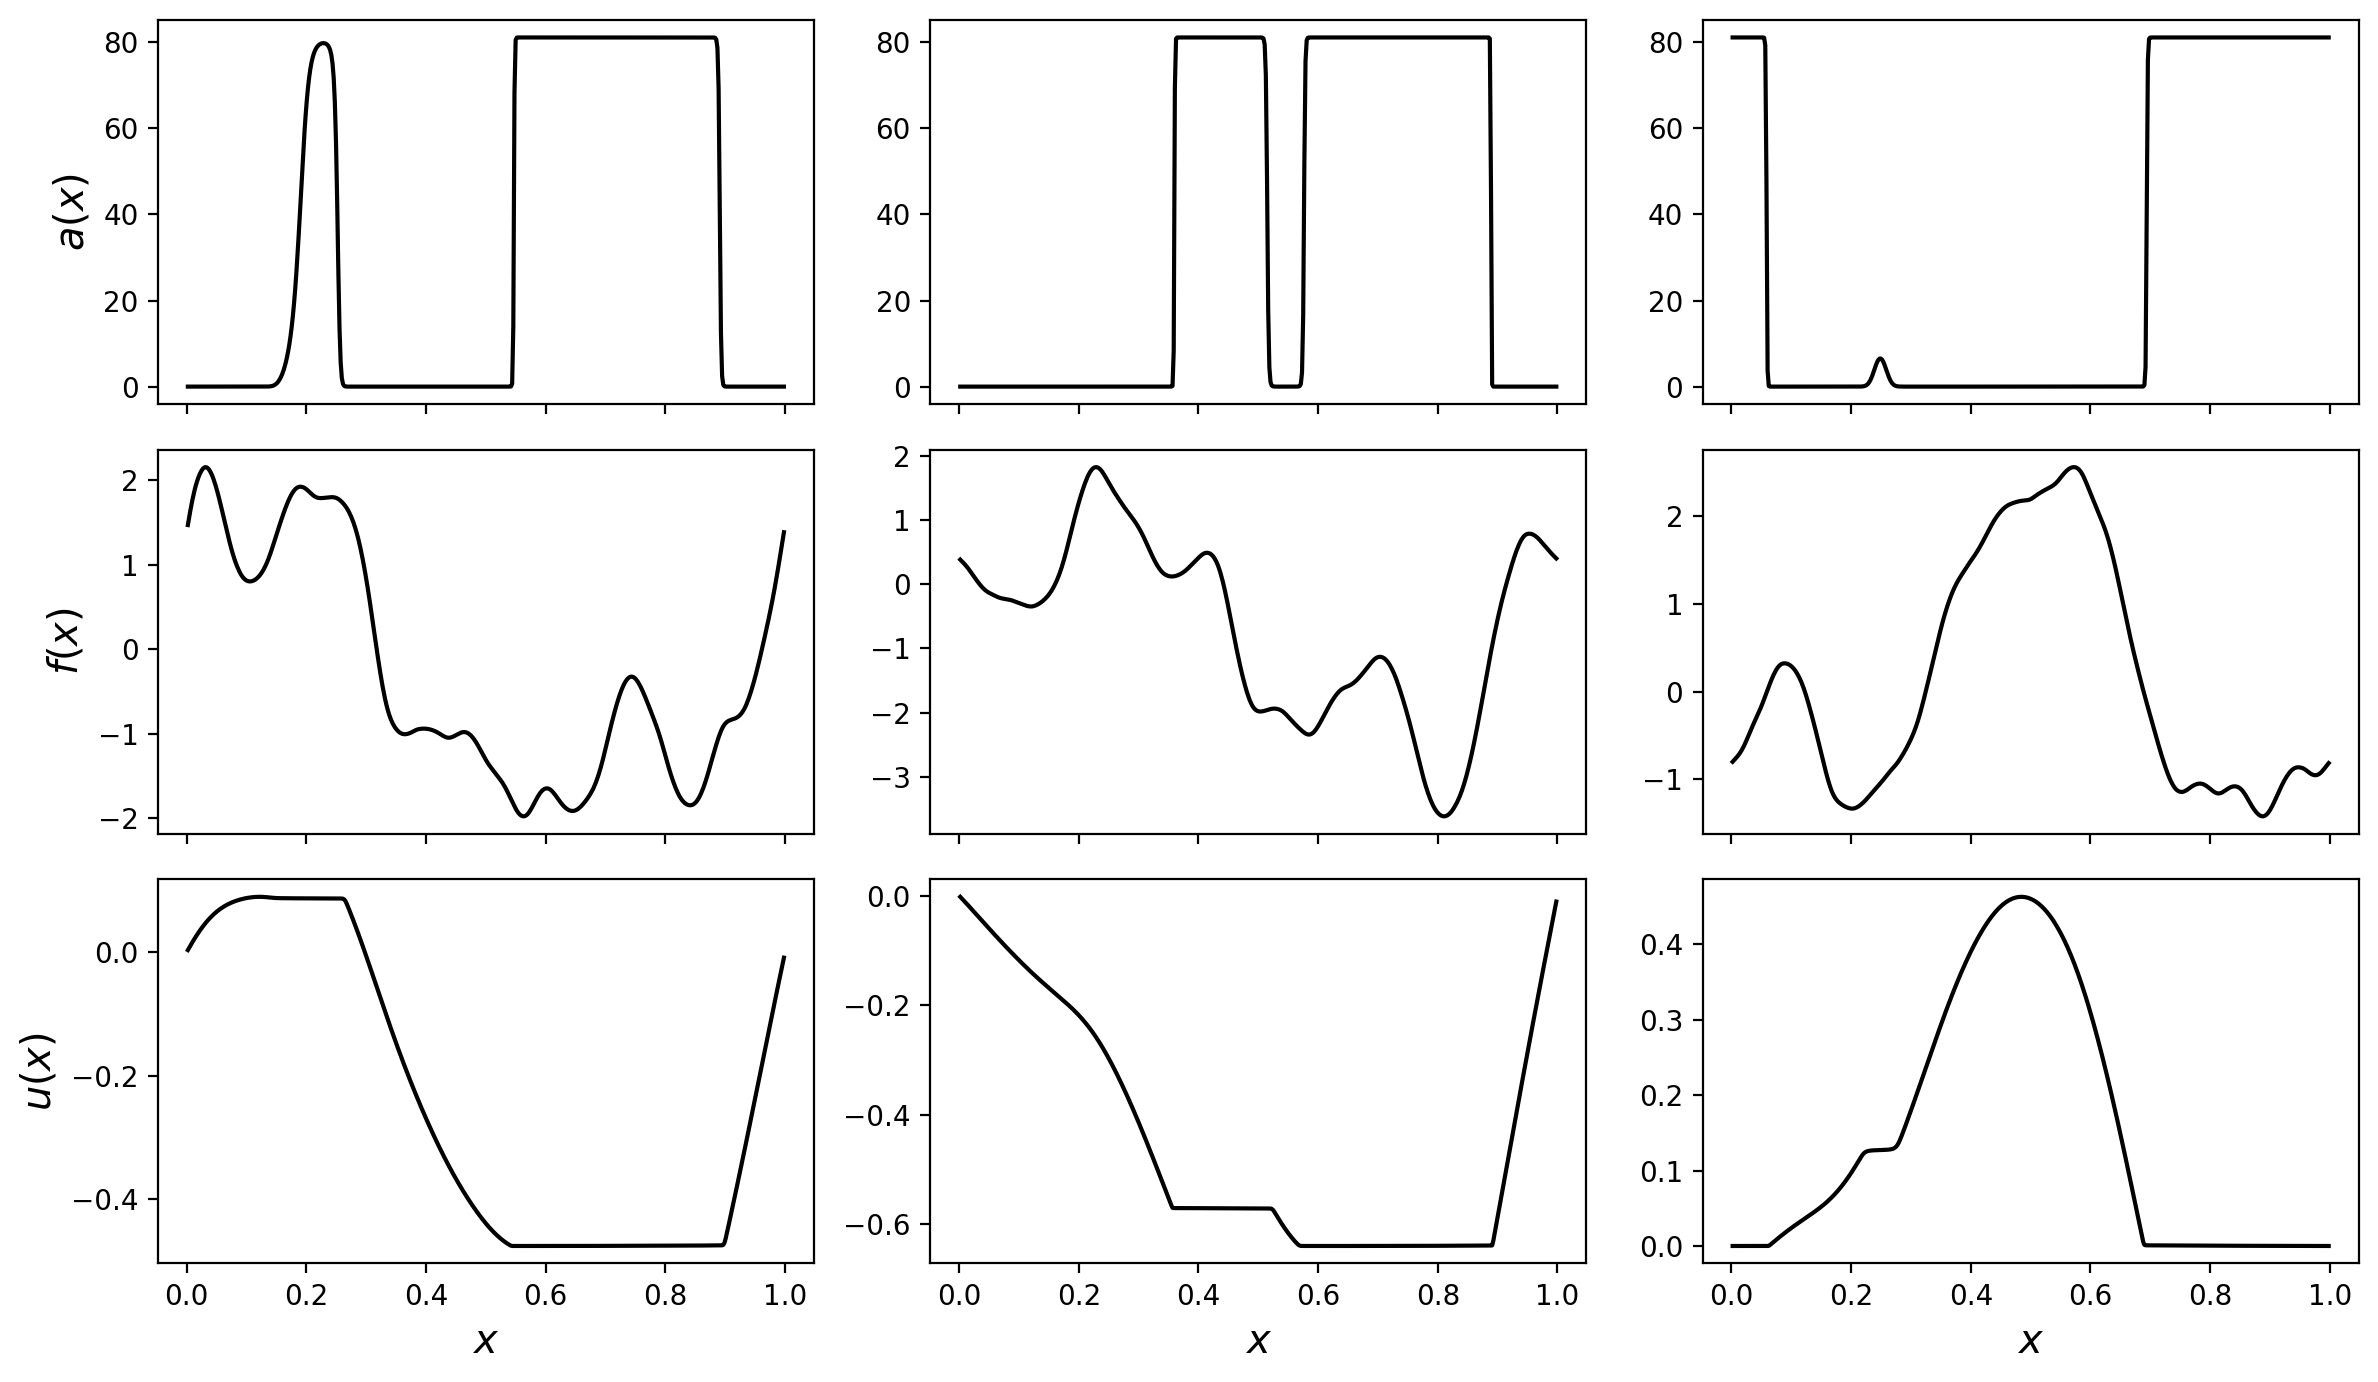

In [7]:
data = get_dataset(random.PRNGKey(71), 1000)
print({k: v.shape for k, v in data.items()})

fig, axes = plt.subplots(3, 3, figsize=(12, 7), sharex=True)
for j in range(3):
    axes[0, j].plot(data["grid points"], data["diffusion coefficient"][j], color="black")
    axes[1, j].plot(data["grid points"], data["righ-hand side"][j], color="black")
    axes[2, j].plot(data["grid points"], data["solution"][j], color="black")
for ax, name in zip(axes[:, 0], ["$a(x)$", "$f(x)$", "$u(x)$"]):
    ax.set_ylabel(name, fontsize='x-large')
for ax in axes[-1]:
    ax.set_xlabel("$x$", fontsize='x-large')
plt.tight_layout()

figure_name = "Diffusion_dataset"
if figure_name is not None:
    # the repository root is the closest parent of the working directory that contains `notebooks`
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
    data_dir = root / "data"
    
    if not data_dir.exists():
        data_dir.mkdir()

    plt.savefig(data_dir / f"{figure_name}.pdf", format='pdf', bbox_inches='tight');

## Saving the dataset

The dataset generated above will be reused in the further tutorials (e.g. to train PINNs and neural operators and to compare them with the FEM solution), so we do not want to recompute it every time. We save it as a `.npz` archive in the folder `data` located in the root of the repository, next to the folder `notebooks`. The cell below creates this folder if it does not exist yet.

In [8]:
from pathlib import Path

# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

if not data_dir.exists():
    data_dir.mkdir()
    print(f"Created {data_dir.relative_to(root)}")
else:
    print(f"{data_dir.relative_to(root)} already exists")

jnp.savez(data_dir / "diffusion_dataset.npz", **data)
print(f"Saved dataset to {(data_dir / 'diffusion_dataset.npz').relative_to(root)}")

data already exists
Saved dataset to data/diffusion_dataset.npz
